# Comparação: Prophet vs. Ensemble (GradientBoosting + RandomForest com Conformal Prediction)

Este notebook compara o modelo de séries temporais **Prophet** (tendência + sazonalidade
semanal/anual via Fourier + efeitos de feriados/férias) com o **ensemble já usado no
projeto** (`VotingRegressor` de GradientBoosting + RandomForest, com intervalos via
Conformal Prediction, como em `Previsao_area1.ipynb` / `Previsao_area2.ipynb`).

O objetivo é ter uma noção **quantitativa** de quanto o Prophet melhora, piora ou empata
com o ensemble atual — tanto na previsão pontual quanto na qualidade dos intervalos de
confiança.

## Como a comparação é feita

- Mesmo split treino/calibração (`train_test_split` com `test_size=0.3`, `random_state=42`)
  usado nos notebooks `Previsao_area1.ipynb` / `Previsao_area2.ipynb`, para que os dois
  modelos sejam avaliados exatamente nas mesmas observações fora da amostra de treino.
- O Prophet exige **uma linha por data** (não aceita datas duplicadas). Como a área 1 tem
  almoço e jantar no mesmo dia, ela é avaliada **separadamente por refeição**. A área 2 já
  tem uma linha por dia, então é avaliada de uma vez só.
- Os feriados e períodos de férias usados no Prophet vêm diretamente de
  `calendario_utils.py` (`FERIADOS` e `FERIAS`) — a mesma fonte usada para gerar
  `calendario.csv` e para as colunas `dias_ate_ferias` etc. usadas pelo ensemble.

## Métricas escolhidas (e por quê)

**Previsão pontual:**
- **MAE** (erro absoluto médio, em nº de pessoas) — direto de interpretar operacionalmente.
- **RMSE** — penaliza mais os erros grandes; relevante porque um erro grande de previsão
  tem custo desproporcional (falta de comida vs. desperdício).
- **MAPE (%)** — erro relativo; permite comparar área 1 e área 2 (escalas diferentes de
  demanda) na mesma régua.

**Qualidade do intervalo de confiança (ambos os modelos entregam intervalo a 95%):**
- **Cobertura (%)** — fração das observações reais que caem dentro do intervalo previsto.
  Idealmente próxima de 95%. Muito abaixo disso indica intervalo mal calibrado (otimista
  demais); muito acima indica intervalo desnecessariamente largo.
- **Amplitude média do intervalo** — quão "estreito" é o intervalo. Entre dois modelos com
  cobertura parecida, o de menor amplitude é mais informativo/útil na prática.


In [2]:
import sys
import logging
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor

from prophet import Prophet

# O Prophet/cmdstanpy imprime muitos logs internos a cada .fit(); como vamos treinar
# dezenas de vezes (várias seeds x vários casos), silenciamos para não poluir a saída.
logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
logging.getLogger('prophet').setLevel(logging.ERROR)

np.random.seed(42)
pd.set_option('display.max_columns', 50)

## Configuração de caminhos (busca automática)

Em vez de caminhos fixos, a célula abaixo **procura automaticamente** `dataatea1clima.csv`,
`dataarea2clima.csv` e `calendario_utils.py` a partir da pasta onde este notebook está rodando
(e de algumas pastas vizinhas/acima), então funciona independente de em qual subpasta do
projeto você colocou este notebook.

Se a busca não encontrar algum arquivo, ela avisa exatamente qual está faltando, e a
célula de diagnóstico logo abaixo te dá um comando para colar aqui no chat, para eu ajustar
os caminhos manualmente.

In [3]:
import os

def _buscar_arquivo(nome, inicio, profundidade_max=4, max_diretorios=20000):
    """Procura recursivamente por 'nome' a partir de 'inicio', com profundidade limitada."""
    inicio = Path(inicio).resolve()
    if not inicio.exists():
        return None
    visitados = 0
    for dirpath, dirnames, filenames in os.walk(inicio):
        visitados += 1
        if visitados > max_diretorios:
            break
        rel_depth = len(Path(dirpath).relative_to(inicio).parts)
        if rel_depth > profundidade_max:
            dirnames[:] = []
            continue
        # não entra em pastas pesadas/irrelevantes
        dirnames[:] = [d for d in dirnames if d not in ('.git', '.ipynb_checkpoints', '__pycache__', 'node_modules', '.venv', 'venv')]
        if nome in filenames:
            return Path(dirpath) / nome
    return None


def localizar_arquivo(nome_arquivo):
    """Tenta achar 'nome_arquivo' partindo da pasta atual e subindo até 3 níveis."""
    candidatos_raiz = [Path('.'), Path('..'), Path('../..'), Path('../../..')]
    for raiz in candidatos_raiz:
        achado = _buscar_arquivo(nome_arquivo, raiz)
        if achado is not None:
            return achado
    return None


DATA_AREA1_PATH = localizar_arquivo('dataatea1clima.csv')
DATA_AREA2_PATH = localizar_arquivo('dataarea2clima.csv')
CALENDARIO_UTILS_PATH = localizar_arquivo('calendario_utils.py')

print("Pasta atual do notebook:", Path('.').resolve())
for nome, caminho in [
    ('dataatea1clima.csv', DATA_AREA1_PATH),
    ('dataarea2clima.csv', DATA_AREA2_PATH),
    ('calendario_utils.py', CALENDARIO_UTILS_PATH),
]:
    status = f"ENCONTRADO em: {caminho}" if caminho else "NAO ENCONTRADO"
    print(f"  {nome}: {status}")

if DATA_AREA1_PATH is None or DATA_AREA2_PATH is None or CALENDARIO_UTILS_PATH is None:
    raise FileNotFoundError(
        "Não foi possível localizar automaticamente um ou mais arquivos (veja acima quais). "
        "Rode a célula de diagnóstico logo abaixo e me envie o resultado, ou ajuste os "
        "caminhos manualmente substituindo as linhas de DATA_AREA1_PATH / DATA_AREA2_PATH / "
        "CALENDARIO_UTILS_PATH por Path('caminho/exato/do/arquivo')."
    )

sys.path.append(str(CALENDARIO_UTILS_PATH.parent.resolve()))
from calendario_utils import FERIADOS, FERIAS

CSV_AREA1 = DATA_AREA1_PATH
CSV_AREA2 = DATA_AREA2_PATH

Pasta atual do notebook: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\notebooks\experimentos_previsao
  dataatea1clima.csv: ENCONTRADO em: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\notebooks\experimentos_previsao\dataatea1clima.csv
  dataarea2clima.csv: ENCONTRADO em: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\notebooks\experimentos_previsao\dataarea2clima.csv
  calendario_utils.py: ENCONTRADO em: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\data\data_treatment_completo\calendario_utils.py


### Se a busca automática falhar

Rode a célula de diagnóstico abaixo e **cole o resultado aqui no chat** — com isso eu
consigo te dar os caminhos exatos (`DATA_AREA1_PATH`, `DATA_AREA2_PATH`,
`CALENDARIO_UTILS_PATH`) para colar de volta na célula acima, sem ficarmos tentando
adivinhar.

In [4]:
# DIAGNÓSTICO — rode só se a busca automática da célula acima não encontrar os arquivos.
# Copie TODO o texto impresso e cole aqui no chat.

import os
from pathlib import Path

def arvore(raiz, profundidade_max=3, max_linhas=300):
    raiz = Path(raiz).resolve()
    linhas = [f"Raiz: {raiz}"]
    contador = 0
    for dirpath, dirnames, filenames in os.walk(raiz):
        dirnames[:] = [d for d in dirnames if d not in ('.git', '.ipynb_checkpoints', '__pycache__', 'node_modules', '.venv', 'venv')]
        rel = Path(dirpath).relative_to(raiz)
        profundidade = len(rel.parts)
        if profundidade > profundidade_max:
            dirnames[:] = []
            continue
        indent = "  " * profundidade
        linhas.append(f"{indent}{rel if str(rel) != '.' else '.'}/")
        for f in sorted(filenames):
            if f.endswith(('.csv', '.py', '.ipynb')):
                linhas.append(f"{indent}  {f}")
                contador += 1
                if contador > max_linhas:
                    linhas.append("... (truncado)")
                    return "\n".join(linhas)
    return "\n".join(linhas)


print("### Pasta atual do notebook ###")
print(Path('.').resolve())
print()
print("### Árvore a partir da pasta atual (até 3 níveis) ###")
print(arvore('.'))
print()
print("### Árvore a partir da pasta acima (..) (até 3 níveis) ###")
print(arvore('..'))

### Pasta atual do notebook ###
C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\notebooks\experimentos_previsao

### Árvore a partir da pasta atual (até 3 níveis) ###
Raiz: C:\Users\lucas\Documents\USP\Python\projeto-ru\previsao\notebooks\experimentos_previsao
./
  Avaliacao_CV_Expansiva_Jitter.ipynb
  Comparacao_Prophet_vs_Ensemble.ipynb
  Experimento_Jittering_SDV.ipynb
  Sweep_EscalaRuido_SoJitterX5_CalibReal.ipynb
  comparacao_janela_expansiva_jitter.ipynb
  comparacao_splits_jitter.py
  dataarea1.csv
  dataarea2.csv
  dataarea2clima.csv
  dataatea1clima.csv
  resultados_comparacao_cv.csv
  resultados_experimento/
    resultados_cenario_A_area1.csv
    resultados_cenario_B_area1.csv
    resultados_cenario_C_area1.csv
    resultados_cenario_D_area1.csv
    resultados_todos_cenarios_area1.csv
    tabela_significancia_area1.csv
  resultados_sweep_escala_ruido/
    sweep_escala_ruido_area1.csv

### Árvore a partir da pasta acima (..) (até 3 níveis) ###
Raiz: C:\Users\lucas\Docu

In [5]:
def expandir_intervalo(item):
    """Converte um item de FERIADOS/FERIAS (data única ou intervalo) numa lista de datas."""
    if isinstance(item, tuple):
        inicio, fim = item
        return list(pd.date_range(inicio, fim))
    return [pd.to_datetime(item)]


def montar_holidays_df(feriados=FERIADOS, ferias=FERIAS):
    """Monta o DataFrame de feriados/eventos no formato exigido pelo Prophet."""

    datas_feriados = sorted({d for item in feriados for d in expandir_intervalo(item)})
    holidays_feriados = pd.DataFrame({
        'holiday': 'feriado',
        'ds': pd.to_datetime(datas_feriados),
        'lower_window': 0,
        'upper_window': 1,  # captura efeito de véspera/pós-feriado
    })

    datas_ferias = sorted({d for item in ferias for d in expandir_intervalo(item)})
    holidays_ferias = pd.DataFrame({
        'holiday': 'ferias',
        'ds': pd.to_datetime(datas_ferias),
        'lower_window': 0,
        'upper_window': 0,
    })

    return pd.concat([holidays_feriados, holidays_ferias], ignore_index=True)


holidays_df = montar_holidays_df()
holidays_df.head()

,holiday,ds,lower_window,upper_window
0,feriado,2023-04-03,0,1
1,feriado,2023-04-04,0,1
2,feriado,2023-04-05,0,1
3,feriado,2023-04-06,0,1
4,feriado,2023-04-07,0,1


## Preparação dos dados

Reproduz exatamente a limpeza feita em `Previsao_area1.ipynb` / `Previsao_area2.ipynb`,
apenas acrescentando a coluna `ds` (data) exigida pelo Prophet.

In [6]:
def carregar_e_preparar(csv_path, is_area1, refeicao_filtro=None, verbose=True):
    """
    Carrega e limpa os dados, reproduzindo os passos de Previsao_area1.ipynb /
    Previsao_area2.ipynb, e adiciona a coluna 'ds' (data) exigida pelo Prophet.

    O dataset original tem algumas poucas linhas duplicadas na chave
    Ano/Mês/Dia_mês(/refeicao) — isso já aparecia no aviso 'Linhas duplicadas' do
    Tratamento_dos_dados.ipynb, mas nunca foi removido lá. Como o Prophet exige uma
    linha por data, removemos aqui (mantendo a primeira ocorrência) e avisamos quantas
    linhas foram descartadas, para não mascarar o problema.
    """
    data = pd.read_csv(csv_path, header=0)

    if is_area1:
        data = data[data['refeicao'] != 'cafe da manha'].copy()
        data = data.dropna()
        data = data[data['total'] != 0]

        if refeicao_filtro is not None:
            data = data[data['refeicao'] == refeicao_filtro].copy()
    # área 2 já não tem NaNs nem coluna 'refeicao' (ver Tratamento_dos_dados.ipynb)

    # --- Remove duplicatas reais de Ano/Mês/Dia_mês(/refeicao) ---
    chave_duplicata = ['Ano', 'Mês', 'Dia_mês'] + (['refeicao'] if is_area1 else [])
    n_antes = len(data)
    data = data.drop_duplicates(subset=chave_duplicata, keep='first').copy()
    n_removidas = n_antes - len(data)
    if n_removidas > 0 and verbose:
        print(
            f"Aviso: removida(s) {n_removidas} linha(s) duplicada(s) em {chave_duplicata} "
            "(mantida a primeira ocorrência de cada data)."
        )

    # Mesmos filtros de "categoria rara" (< 5 ocorrências) usados nos notebooks originais
    data = data.groupby("guarnição").filter(lambda x: len(x) >= 5)
    data = data.groupby("prato_principal_1").filter(lambda x: len(x) >= 5)
    data = data.groupby("prato_principal_2").filter(lambda x: len(x) >= 5)
    data = data.groupby("sobremesa_1").filter(lambda x: len(x) >= 5)

    data['ds'] = pd.to_datetime(
        data['Ano'].astype(str) + '-' + data['Mês'].astype(str) + '-' + data['Dia_mês'].astype(str),
        format='%Y-%m-%d',
    )

    if data['ds'].duplicated().any():
        # Não deveria mais acontecer após a deduplicação acima, mas mantemos a checagem
        # como rede de segurança (ex.: se novas duplicatas de outro tipo aparecerem).
        raise ValueError(
            "Ainda há datas duplicadas mesmo após a deduplicação — verifique se "
            "`refeicao_filtro` foi definido para a área 1, e investigue a chave "
            f"{chave_duplicata} no CSV de origem."
        )

    return data.reset_index(drop=True)


def montar_X_y(data, onehot_cols):
    """Reproduz o one-hot encoding e a montagem de X/y dos notebooks originais."""
    data_raw_base = data.copy()
    colunas_base = data_raw_base.drop(columns=['total', 'ds']).columns

    data_onehot = pd.get_dummies(data, columns=onehot_cols)

    atributos = data_onehot.drop(columns=['total', 'ds']).columns
    X = data_onehot[atributos]
    y = data_onehot['total']

    return data_raw_base, X, y, atributos, colunas_base

## Modelo 1 — Ensemble (VotingRegressor GB + RF) com Conformal Prediction

Função copiada de `Previsao_area1.ipynb` / `Previsao_area2.ipynb`, sem alterações na lógica,
mais uma função auxiliar para reconstruir o intervalo por observação de calibração.

In [7]:
def treinar_ensemble_conformal(X, y, alpha=0.05, test_size=0.3, random_state=42):
    """
    Treina o ensemble de conformal prediction e calcula as margens do intervalo.
    (idêntico ao usado em Previsao_area1.ipynb / Previsao_area2.ipynb)
    """
    nivel_confianca = 1 - alpha

    X_train, X_calib, y_train, y_calib = train_test_split(
        X, y, test_size=test_size, random_state=random_state
    )

    ensemble_conformal = VotingRegressor(
        estimators=[('gb', GradientBoostingRegressor(n_estimators=200, random_state=random_state)),
                    ('rf', RandomForestRegressor(n_estimators=200, random_state=random_state))],
        weights=[3, 1]
    )
    ensemble_conformal.fit(X_train, y_train)

    y_calib_pred = ensemble_conformal.predict(X_calib)
    residuos_calib = np.abs(y_calib - y_calib_pred)

    mascara_transicao = (X_calib['dias_desde_ultimas_ferias'] <= 10) | (X_calib['dias_ate_ferias'] <= 10)
    residuos_transicao = residuos_calib[mascara_transicao]
    residuos_normais = residuos_calib[~mascara_transicao]

    margem_transicao = np.quantile(residuos_transicao, nivel_confianca, method='higher')
    margem_normal = np.quantile(residuos_normais, nivel_confianca, method='higher')

    ensemble = VotingRegressor(
        estimators=[('gb', GradientBoostingRegressor(n_estimators=200, random_state=random_state)),
                    ('rf', RandomForestRegressor(n_estimators=200, random_state=random_state))],
        weights=[3, 1]
    )
    ensemble.fit(X, y)

    return {
        'ensemble': ensemble,
        'X_train': X_train,
        'X_calib': X_calib,
        'y_train': y_train,
        'y_calib': y_calib,
        'y_calib_pred': y_calib_pred,
        'margem_transicao': margem_transicao,
        'margem_normal': margem_normal,
        'nivel_confianca': nivel_confianca,
        'alpha': alpha,
    }


def intervalo_ensemble(resultado_treino, y_min):
    """Constrói os limites inferior/superior do intervalo do ensemble para X_calib."""
    X_calib = resultado_treino['X_calib']
    y_calib_pred = resultado_treino['y_calib_pred']

    mascara_transicao = (X_calib['dias_desde_ultimas_ferias'] <= 10) | (X_calib['dias_ate_ferias'] <= 10)
    margem = np.where(
        mascara_transicao,
        resultado_treino['margem_transicao'],
        resultado_treino['margem_normal'],
    )

    limite_inf = np.maximum(y_min, y_calib_pred - margem)
    limite_sup = y_calib_pred + margem
    return limite_inf, limite_sup

## Modelo 2 — Prophet

Treinado **apenas com as datas de treino** (as mesmas usadas pelo ensemble) e avaliado
nas **mesmas datas de calibração**, garantindo que os dois modelos vejam exatamente a
mesma divisão treino/teste.

In [8]:
def treinar_prophet(data_raw_base, idx_train, idx_calib, holidays_df,
                     yearly_fourier=10, weekly_fourier=3, interval_width=0.95):
    """Treina o Prophet nas datas de treino e prevê nas datas de calibração."""

    df_train = (
        data_raw_base.loc[idx_train, ['ds', 'total']]
        .rename(columns={'total': 'y'})
        .sort_values('ds')
        .reset_index(drop=True)
    )

    m = Prophet(
        holidays=holidays_df,
        yearly_seasonality=yearly_fourier,
        weekly_seasonality=weekly_fourier,
        daily_seasonality=False,
        interval_width=interval_width,
    )
    m.fit(df_train)

    df_calib = (
        data_raw_base.loc[idx_calib, ['ds']]
        .sort_values('ds')
        .reset_index(drop=True)
    )
    forecast = m.predict(df_calib)

    # Junta com o valor real (por data) para poder calcular as métricas
    y_real = data_raw_base.loc[idx_calib, ['ds', 'total']]
    avaliacao = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].merge(y_real, on='ds', how='left')

    return m, forecast, avaliacao

## Métricas de comparação

`calcular_metricas` devolve MAE/RMSE/MAPE sempre, e Cobertura/Amplitude quando um
intervalo (`y_lower`, `y_upper`) é passado — o que vale tanto para o ensemble quanto
para o Prophet, já que os dois entregam intervalo a 95%.

In [9]:
def calcular_metricas(y_true, y_pred, y_lower=None, y_upper=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    erro = y_true - y_pred
    mae = np.mean(np.abs(erro))
    rmse = np.sqrt(np.mean(erro ** 2))

    with np.errstate(divide='ignore', invalid='ignore'):
        ape = np.abs(erro) / np.where(y_true == 0, np.nan, y_true)
    mape = np.nanmean(ape) * 100

    metrics = {'MAE': mae, 'RMSE': rmse, 'MAPE (%)': mape}

    if y_lower is not None and y_upper is not None:
        y_lower = np.asarray(y_lower, dtype=float)
        y_upper = np.asarray(y_upper, dtype=float)
        cobertura = np.mean((y_true >= y_lower) & (y_true <= y_upper)) * 100
        amplitude_media = np.mean(y_upper - y_lower)
        metrics['Cobertura (%)'] = cobertura
        metrics['Amplitude média do intervalo'] = amplitude_media

    return metrics

## Pipeline completo por caso (área + refeição), repetido com várias seeds

Um único split treino/calibração pode fazer um modelo parecer melhor só por sorte
daquela divisão específica. Para não tirar conclusão de um resultado que pode ser
fruto do acaso, cada caso é rodado **`N_REPETICOES` vezes**, cada vez com uma seed
diferente de `train_test_split` — e comparamos a **média ± desvio-padrão** de cada
métrica entre as repetições, além do resultado de uma execução específica (para os
gráficos, que não fazem sentido serem repetidos 15x).

Se a diferença entre Prophet e Ensemble for grande e consistente em relação ao
desvio-padrão entre as repetições, é um sinal de que a diferença é real. Se o
desvio-padrão for da mesma ordem de grandeza da diferença entre os modelos, a
diferença pode não ser confiável.

Casos avaliados:
- Área 1 — Almoço
- Área 1 — Jantar
- Área 2 — Almoço (única refeição disponível nos dados)

In [10]:
ONEHOT_COLS_AREA1 = ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                     'prato_principal_2', 'guarnição', 'sobremesa_1', 'refeicao']
ONEHOT_COLS_AREA2 = ['Mês', 'Dia_semana', 'Dia_mês', 'prato_principal_1',
                     'prato_principal_2', 'guarnição', 'sobremesa_1']

In [11]:
N_REPETICOES = 15   # numero de splits diferentes testados por caso
SEED_REFERENCIA = 42  # seed usada para os graficos (real vs previsto, residuos, decomposicao)


def comparar_caso(nome_caso, csv_path, is_area1, onehot_cols, holidays_df, refeicao_filtro=None,
                   random_state=42, verbose=True):
    """Roda o Ensemble e o Prophet uma única vez, com um split fixo (dado por random_state)."""
    if verbose:
        print(f"\n{'=' * 70}\n{nome_caso} (seed={random_state})\n{'=' * 70}")

    data = carregar_e_preparar(csv_path, is_area1=is_area1, refeicao_filtro=refeicao_filtro, verbose=verbose)
    data_raw_base, X, y, atributos, colunas_base = montar_X_y(data, onehot_cols)

    # --- Ensemble ---
    resultado_treino = treinar_ensemble_conformal(X, y, alpha=0.05, test_size=0.3, random_state=random_state)
    limite_inf_ens, limite_sup_ens = intervalo_ensemble(resultado_treino, y.min())
    metricas_ensemble = calcular_metricas(
        resultado_treino['y_calib'], resultado_treino['y_calib_pred'],
        limite_inf_ens, limite_sup_ens,
    )

    # --- Prophet (mesmas datas de treino/calibração do ensemble) ---
    idx_train = resultado_treino['X_train'].index
    idx_calib = resultado_treino['X_calib'].index
    m_prophet, forecast, avaliacao_prophet = treinar_prophet(
        data_raw_base, idx_train, idx_calib, holidays_df,
    )
    metricas_prophet = calcular_metricas(
        avaliacao_prophet['total'], avaliacao_prophet['yhat'],
        avaliacao_prophet['yhat_lower'], avaliacao_prophet['yhat_upper'],
    )

    if verbose:
        tabela = pd.DataFrame({'Ensemble (atual)': metricas_ensemble, 'Prophet': metricas_prophet}).T
        print(tabela.round(2))

    return {
        'nome_caso': nome_caso,
        'random_state': random_state,
        'data_raw_base': data_raw_base,
        'resultado_treino': resultado_treino,
        'limite_inf_ens': limite_inf_ens,
        'limite_sup_ens': limite_sup_ens,
        'modelo_prophet': m_prophet,
        'forecast_prophet': forecast,
        'avaliacao_prophet': avaliacao_prophet,
        'metricas_ensemble': metricas_ensemble,
        'metricas_prophet': metricas_prophet,
    }


def comparar_caso_multiplo(nome_caso, csv_path, is_area1, onehot_cols, holidays_df,
                            refeicao_filtro=None, n_repeticoes=N_REPETICOES,
                            seed_referencia=SEED_REFERENCIA):
    """
    Roda `comparar_caso` várias vezes (uma por seed), para checar se a diferença entre
    Prophet e Ensemble se mantém em vários splits ou é efeito de um split específico
    'de sorte'. Guarda também o resultado completo da seed de referência, para os
    gráficos (real vs. previsto, resíduos, decomposição do Prophet).
    """
    print(f"\n{'#' * 70}\n{nome_caso} — {n_repeticoes} repeticoes com seeds diferentes\n{'#' * 70}")

    seeds = list(range(n_repeticoes))
    if seed_referencia not in seeds:
        seeds[0] = seed_referencia  # garante que a seed de referencia esta incluida

    linhas_metricas = []
    resultado_referencia = None

    for seed in seeds:
        r = comparar_caso(
            nome_caso, csv_path, is_area1=is_area1, onehot_cols=onehot_cols,
            holidays_df=holidays_df, refeicao_filtro=refeicao_filtro,
            random_state=seed, verbose=False,
        )
        for modelo, metricas in [('Ensemble', r['metricas_ensemble']), ('Prophet', r['metricas_prophet'])]:
            linha = {'seed': seed, 'Modelo': modelo}
            linha.update(metricas)
            linhas_metricas.append(linha)

        if seed == seed_referencia:
            resultado_referencia = r

        print(f"  seed {seed} concluida")

    tabela_execucoes = pd.DataFrame(linhas_metricas)

    colunas_metricas = [c for c in tabela_execucoes.columns if c not in ('seed', 'Modelo')]
    resumo = (
        tabela_execucoes
        .groupby('Modelo')[colunas_metricas]
        .agg(['mean', 'std'])
    )

    print(f"\nResumo de {n_repeticoes} execucoes (media +/- desvio-padrao):")
    print(resumo.round(2))

    return {
        'nome_caso': nome_caso,
        'tabela_execucoes': tabela_execucoes,
        'resumo': resumo,
        'resultado_referencia': resultado_referencia,
    }


resultados_multiplos = {}

resultados_multiplos['area1_almoco'] = comparar_caso_multiplo(
    "Área 1 — Almoço", CSV_AREA1, is_area1=True, onehot_cols=ONEHOT_COLS_AREA1,
    holidays_df=holidays_df, refeicao_filtro='almoco',
)

resultados_multiplos['area1_jantar'] = comparar_caso_multiplo(
    "Área 1 — Jantar", CSV_AREA1, is_area1=True, onehot_cols=ONEHOT_COLS_AREA1,
    holidays_df=holidays_df, refeicao_filtro='jantar',
)

resultados_multiplos['area2'] = comparar_caso_multiplo(
    "Área 2 — Almoço", CSV_AREA2, is_area1=False, onehot_cols=ONEHOT_COLS_AREA2,
    holidays_df=holidays_df, refeicao_filtro=None,
)


######################################################################
Área 1 — Almoço — 15 repeticoes com seeds diferentes
######################################################################


c:\Users\lucas\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
11:57:04 - cmdstanpy - INFO - Chain [1] start processing
11:57:05 - cmdstanpy - INFO - Chain [1] done processing


  seed 42 concluida


11:57:09 - cmdstanpy - INFO - Chain [1] start processing
11:57:09 - cmdstanpy - INFO - Chain [1] done processing


  seed 1 concluida


11:57:13 - cmdstanpy - INFO - Chain [1] start processing
11:57:13 - cmdstanpy - INFO - Chain [1] done processing


... (81 outputs left out)

11:59:41 - cmdstanpy - INFO - Chain [1] start processing
11:59:41 - cmdstanpy - INFO - Chain [1] done processing


  seed 13 concluida


11:59:44 - cmdstanpy - INFO - Chain [1] start processing
11:59:44 - cmdstanpy - INFO - Chain [1] done processing


  seed 14 concluida

Resumo de 15 execucoes (media +/- desvio-padrao):
            MAE          RMSE       MAPE (%)       Cobertura (%)        \
           mean   std    mean   std     mean   std          mean   std   
Modelo                                                                   
Ensemble  54.07  3.60   77.77  7.47    17.36  1.27         95.63  0.20   
Prophet   91.10  3.31  114.18  4.37    31.44  3.46         93.59  1.82   

         Amplitude média do intervalo         
                                 mean    std  
Modelo                                        
Ensemble                       286.73  32.81  
Prophet                        421.08   7.05  


## Tabela consolidada (todos os casos, média ± desvio-padrão em N_REPETICOES execuções)

In [15]:
tabelas_resumo = []
for chave, r in resultados_multiplos.items():
    resumo = r['resumo'].copy()
    resumo.index = pd.MultiIndex.from_product([[r['nome_caso']], resumo.index], names=['Caso', 'Modelo'])
    tabelas_resumo.append(resumo)

tabela_geral_multipla = pd.concat(tabelas_resumo)
tabela_geral_multipla.round(2)

MAE           RMSE        MAPE (%)        \
                            mean    std    mean    std     mean   std   
Caso            Modelo                                                  
Área 1 — Almoço Ensemble  133.27   9.12  178.31  13.61     9.57  1.05   
                Prophet   201.71  11.53  262.08  11.95    17.03  1.85   
Área 1 — Jantar Ensemble  128.54   9.29  169.80  13.18     9.74  0.85   
                Prophet   174.46   5.77  221.61   8.38    15.02  1.03   
Área 2 — Almoço Ensemble   54.07   3.60   77.77   7.47    17.36  1.27   
                Prophet    91.10   3.31  114.18   4.37    31.44  3.46   

                         Cobertura (%)       Amplitude média do intervalo  \
                                  mean   std                         mean   
Caso            Modelo                                                      
Área 1 — Almoço Ensemble         95.58  0.13                       748.77   
                Prophet          92.42  1.82                       946.60   
Área 1 — Jantar Ensemble         95.56  0.20                       655.82   
                Prophet          92.77  2.09                       793.81   
Área 2 — Almoço Ensemble         95.63  0.20                       286.73   
                Prophet          93.59  1.82                       421.08   

                                 
                            std  
Caso            Modelo           
Área 1 — Almoço Ensemble  79.94  
                Prophet   19.75  
Área 1 — Jantar Ensemble  51.24  
                Prophet   15.55  
Área 2 — Almoço Ensemble  32.81  
                Prophet    7.05

## Visualizações

Para cada caso:
1. **Boxplot da distribuição das métricas** ao longo das `N_REPETICOES` execuções —
   Ensemble vs. Prophet lado a lado, para ver não só a média mas a variabilidade.
2. **Real vs. previsto** (Ensemble e Prophet) ordenado no tempo — usando apenas a
   execução da seed de referência (`SEED_REFERENCIA`), já que plotar 15 séries
   sobrepostas não ajudaria a visualização.
3. **Histograma comparativo de resíduos** (mesma seed de referência).
4. **Decomposição do Prophet** (tendência, sazonalidade semanal, sazonalidade anual e
   efeitos de feriados/férias), também da seed de referência.

TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'. Did you mean 'label'?

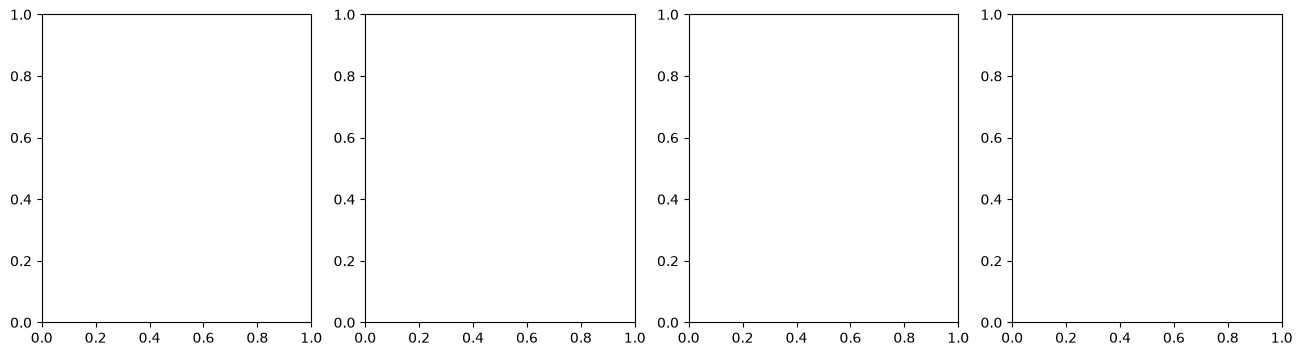

In [19]:
def plotar_distribuicao_metricas(r):
    """Boxplot comparando Ensemble vs Prophet ao longo das N_REPETICOES execuções."""
    tabela = r['tabela_execucoes']
    metricas_para_plotar = [c for c in ['MAE', 'RMSE', 'MAPE (%)', 'Cobertura (%)'] if c in tabela.columns]

    fig, axes = plt.subplots(1, len(metricas_para_plotar), figsize=(4 * len(metricas_para_plotar), 4))
    if len(metricas_para_plotar) == 1:
        axes = [axes]

    for ax, metrica in zip(axes, metricas_para_plotar):
        dados_ensemble = tabela.loc[tabela['Modelo'] == 'Ensemble', metrica]
        dados_prophet = tabela.loc[tabela['Modelo'] == 'Prophet', metrica]
        ax.boxplot([dados_ensemble, dados_prophet], labels=['Ensemble', 'Prophet'])
        ax.set_title(metrica)
        if metrica == 'Cobertura (%)':
            ax.axhline(95, color='red', linestyle='--', linewidth=1, label='Nominal (95%)')
            ax.legend(fontsize=8)

    n_exec = tabela['seed'].nunique()
    fig.suptitle(f"{r['nome_caso']} — distribuição das métricas em {n_exec} execuções (seeds diferentes)")
    plt.tight_layout()
    plt.show()


def plotar_comparacao(r):
    """Real vs. previsto e resíduos, usando o resultado de UMA execução (a seed de referência)."""
    data_raw_base = r['data_raw_base']
    resultado_treino = r['resultado_treino']
    avaliacao_prophet = r['avaliacao_prophet']

    idx_calib = resultado_treino['X_calib'].index
    datas_calib = data_raw_base.loc[idx_calib, 'ds']
    y_calib = resultado_treino['y_calib']
    y_pred_ens = resultado_treino['y_calib_pred']

    df_plot_ens = pd.DataFrame({
        'ds': datas_calib.values, 'real': y_calib.values, 'previsto': y_pred_ens,
    }).sort_values('ds')

    df_plot_prophet = avaliacao_prophet.sort_values('ds')

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

    axes[0].plot(df_plot_ens['ds'], df_plot_ens['real'], label='Real', color='black', linewidth=1)
    axes[0].plot(df_plot_ens['ds'], df_plot_ens['previsto'], label='Ensemble (previsto)', alpha=0.8)
    axes[0].set_title(f"{r['nome_caso']} (seed={r['random_state']}) — Ensemble: real vs. previsto (calibração)")
    axes[0].set_ylabel('Total')
    axes[0].legend()

    axes[1].plot(df_plot_prophet['ds'], df_plot_prophet['total'], label='Real', color='black', linewidth=1)
    axes[1].plot(df_plot_prophet['ds'], df_plot_prophet['yhat'], label='Prophet (previsto)', alpha=0.8, color='tab:orange')
    axes[1].fill_between(
        df_plot_prophet['ds'], df_plot_prophet['yhat_lower'], df_plot_prophet['yhat_upper'],
        alpha=0.2, color='tab:orange', label='Intervalo 95% (Prophet)',
    )
    axes[1].set_title(f"{r['nome_caso']} (seed={r['random_state']}) — Prophet: real vs. previsto (calibração)")
    axes[1].set_ylabel('Total')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    # Resíduos lado a lado
    residuo_ens = df_plot_ens['real'].to_numpy() - df_plot_ens['previsto'].to_numpy()
    residuo_prophet = df_plot_prophet['total'].to_numpy() - df_plot_prophet['yhat'].to_numpy()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
    axes[0].hist(residuo_ens, bins=30, alpha=0.8, color='tab:blue')
    axes[0].axvline(0, color='black', linewidth=1)
    axes[0].set_title('Resíduos — Ensemble')
    axes[0].set_xlabel('Real - Previsto')

    axes[1].hist(residuo_prophet, bins=30, alpha=0.8, color='tab:orange')
    axes[1].axvline(0, color='black', linewidth=1)
    axes[1].set_title('Resíduos — Prophet')
    axes[1].set_xlabel('Real - Previsto')

    plt.suptitle(f"{r['nome_caso']} (seed={r['random_state']})")
    plt.tight_layout()
    plt.show()


for r in resultados_multiplos.values():
    plotar_distribuicao_metricas(r)

for r in resultados_multiplos.values():
    plotar_comparacao(r['resultado_referencia'])


Área 1 — Almoço (seed=42) — decomposição do Prophet (tendência, sazonalidade, feriados/férias)


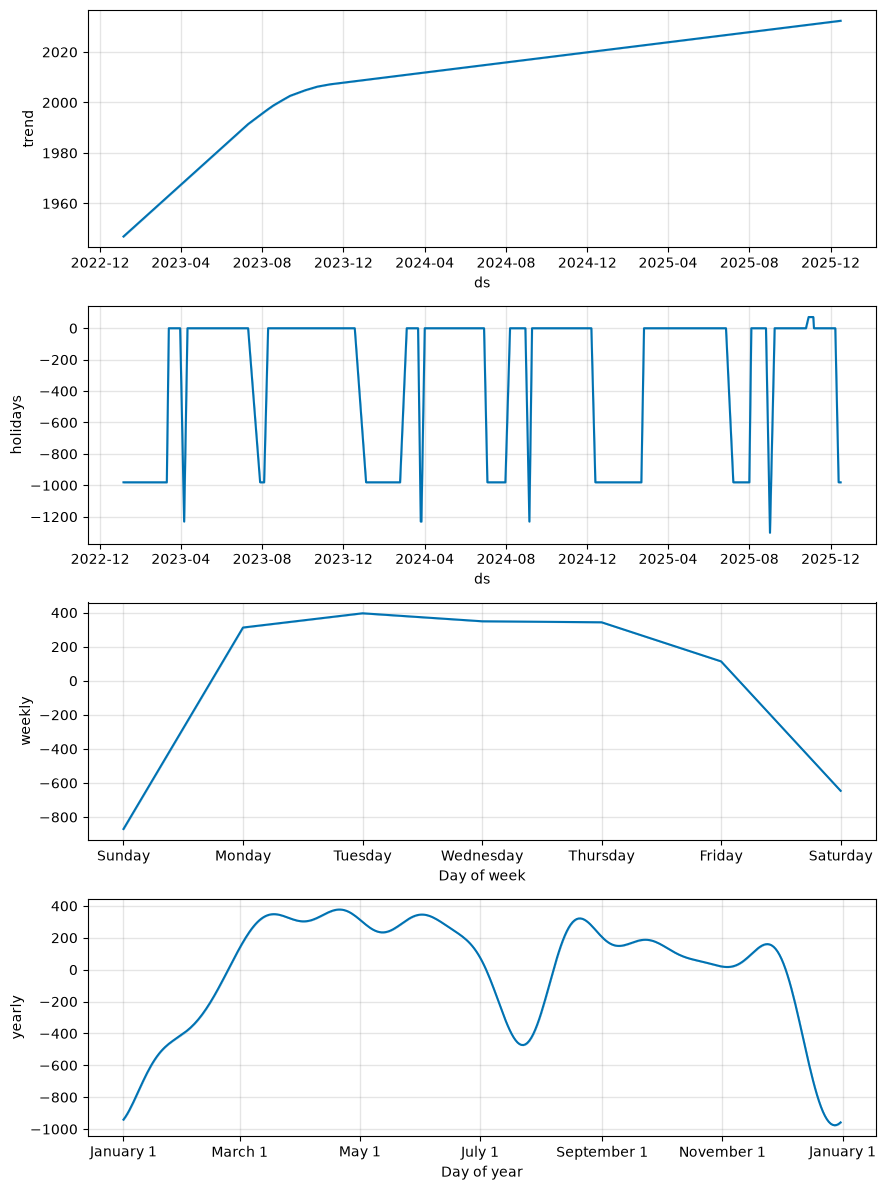


Área 1 — Jantar (seed=42) — decomposição do Prophet (tendência, sazonalidade, feriados/férias)


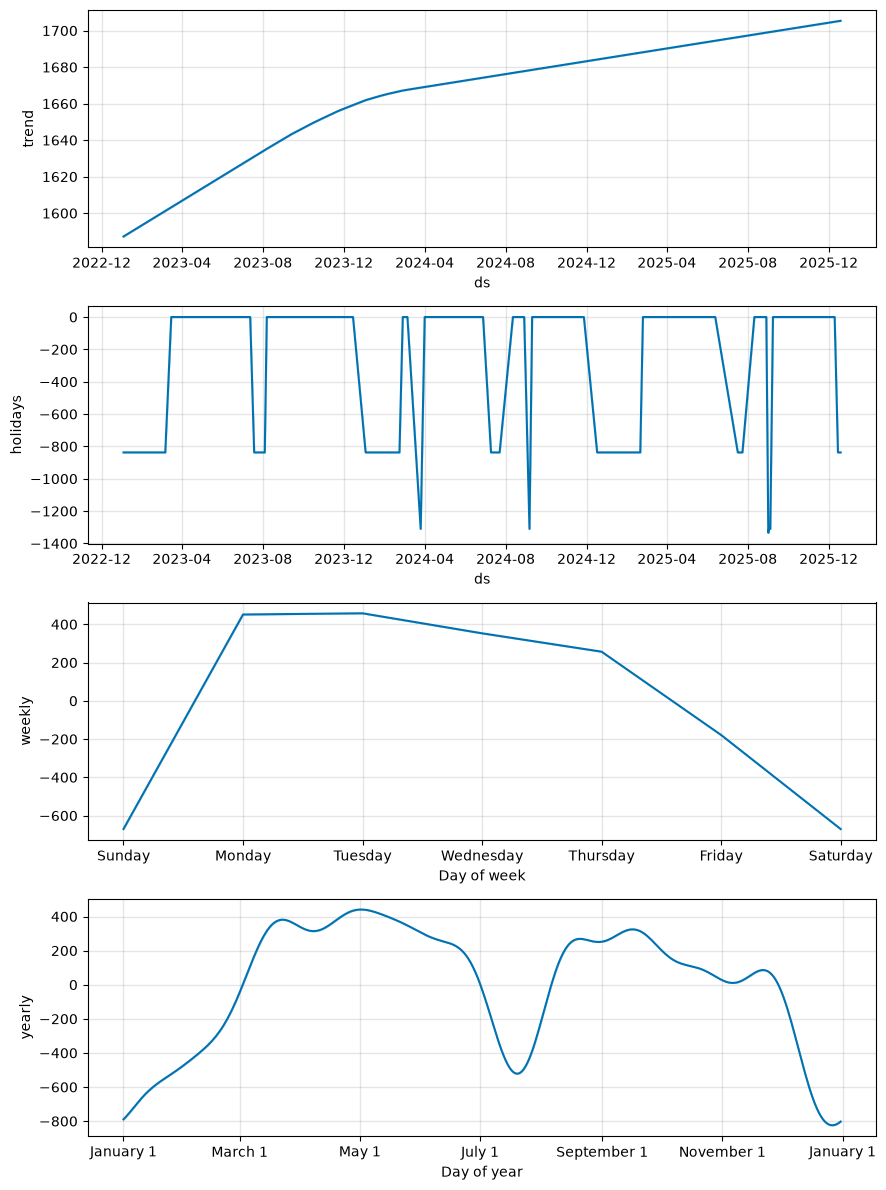


Área 2 — Almoço (seed=42) — decomposição do Prophet (tendência, sazonalidade, feriados/férias)


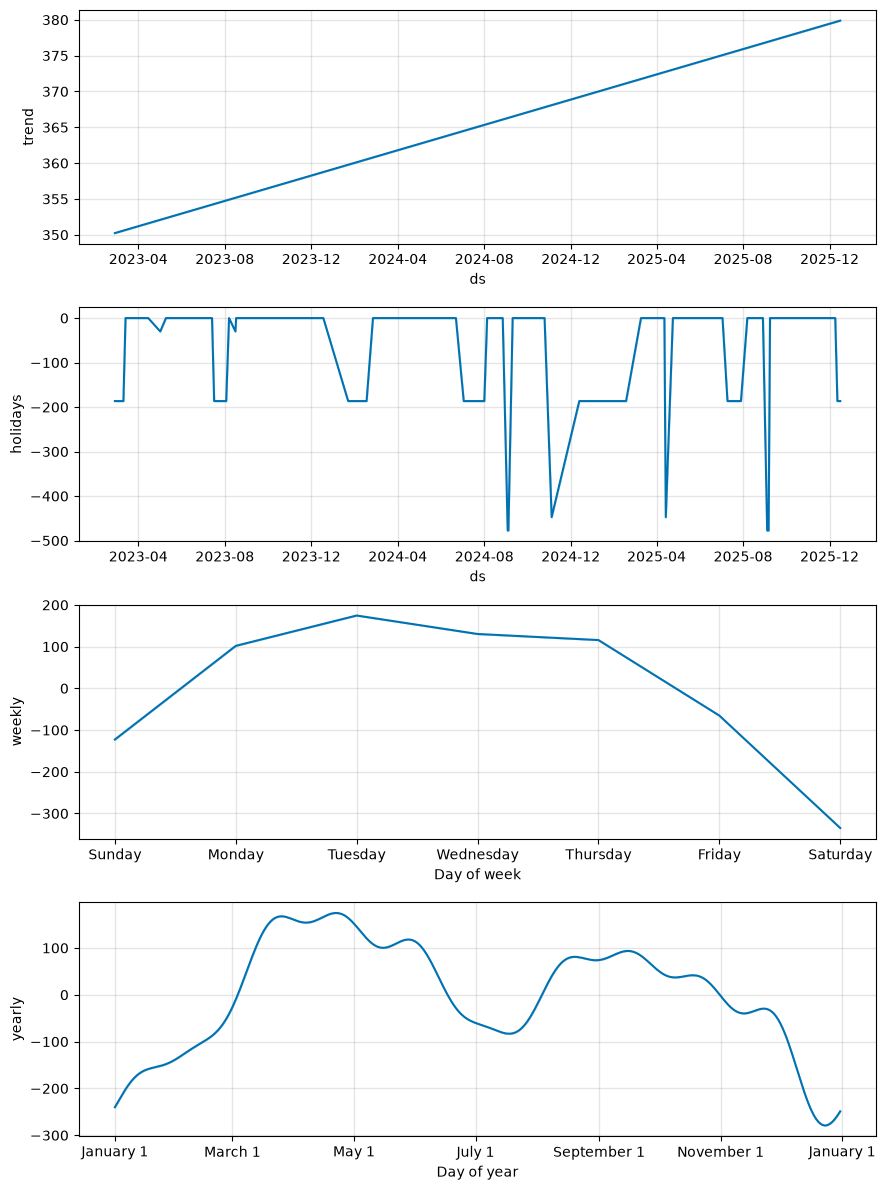

In [20]:
for r in resultados_multiplos.values():
    ref = r['resultado_referencia']
    print(f"\n{ref['nome_caso']} (seed={ref['random_state']}) — decomposição do Prophet (tendência, sazonalidade, feriados/férias)")
    fig = ref['modelo_prophet'].plot_components(ref['forecast_prophet'])
    plt.show()